# Laboratorio 3 · PaySim adaptado
Regresión lineal supervisada del conteo horario

**David Nuncira · Juan Valderrama · Daniel Carrillo**

UPTC · Estadística para Analítica de Datos · 2026-II

## 1. Introducción y objetivo

Este Laboratorio 3 continúa el PaySim adaptado de los Laboratorios 1 y 2. Equipo: David Nuncira, Juan Valderrama y Daniel Carrillo, nombres respaldados por el README de GitHub. Asignatura: Estadística para Analítica de Datos; profesor Duván Cataño, UPTC, 2026-II.

Objetivo: pronosticar el conteo de transacciones de la próxima hora simulada usando regresión lineal supervisada. La unidad cambia de transacción (6.362.620 filas, 7 columnas) a hora (743 observaciones). El objetivo es cuantitativo discreto, por lo que se elige la rama de regresión de la guía, no regresión logística. Se comparan modelos lineales con y sin variables temporales y cinco referencias simples. No se atribuyen etiquetas de fraude al dataset adaptado.

La guía adjunta exige nueve apartados en notebook y una aplicación Streamlit con descripción, visualizaciones, predicciones e inputs. Todos están implementados. SARIMA se deja como trabajo posterior opcional: el requisito de regresión lineal queda cubierto sin sustituirlo por SARIMA.

In [1]:
# En Colab: subir y extraer laboratorio_3_paysim.zip en /content.
# Si faltan bibliotecas, ejecutar una vez: %pip install -r requirements.txt
from pathlib import Path
import sys, json
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/laboratorio_3_paysim')]
ROOT = next((p for p in candidates if (p/'src/modeling.py').exists()), None)
if ROOT is None: raise FileNotFoundError('Extrae el proyecto completo y abre este notebook desde su carpeta.')
sys.path.insert(0,str(ROOT))
from src.modeling import *
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scripts.run_analysis import run
summary=run()  # Recalcula tablas y gráficos a partir de la serie incluida.
display(pd.Series(summary))

{
  "n_transacciones": 6362620,
  "n_horas": 743,
  "n_supervisadas": 719,
  "modelo_seleccionado_validacion_MAE": "lineal_lags",
  "baseline_seleccionado_validacion_MAE": "estacional_24",
  "test_MAE_lineal": 1040.0608237515053,
  "test_MAE_baseline": 1421.375,
  "mejora_MAE_pct_vs_baseline": 26.8271340250458,
  "sha256_hourly": "43fa3acbfe4217b1d6224beef314326c72365b4fdd54b6152bf8e8e0bad36f1a",
  "protocol": "rolling one-step, parámetros congelados, lags reales previos disponibles; recorte a cero predefinido",
  "python": "3.12.14",
  "versions": {
    "pandas": "3.1.1",
    "numpy": "2.5.4",
    "scikit-learn": "1.9.1",
    "statsmodels": "0.15.0",
    "streamlit": "1.66.1"
  }
}


n_transacciones                                                                   6362620
n_horas                                                                               743
n_supervisadas                                                                        719
modelo_seleccionado_validacion_MAE                                            lineal_lags
baseline_seleccionado_validacion_MAE                                        estacional_24
test_MAE_lineal                                                               1040.060824
test_MAE_baseline                                                                1421.375
mejora_MAE_pct_vs_baseline                                                      26.827134
sha256_hourly                           43fa3acbfe4217b1d6224beef314326c72365b4fdd54b6...
protocol                                rolling one-step, parámetros congelados, lags ...
python                                                                            3.12.14
versions  

## 2. Descripción de variables

Esquema original: id_transaccion (identificador nominal), step (hora simulada discreta), tipo_transaccion (CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER), monto (continua en unidades del simulador), cuenta_origen y cuenta_destino (identificadores nominales), tipo_cuenta_destino (CLIENTE/COMERCIO). Se conserva el diccionario del Laboratorio 2 como fuente.

Variable objetivo y_t = transacciones_hora, conteo por step. Predictores: lag_1=y_(t-1), lag_24=y_(t-24). Variante temporal: step (tendencia conocida), sin(2πt/24), cos(2πt/24), sin(2πt/12), cos(2πt/12). La fase es step % 24; no se asigna día de semana, festivos ni una fecha civil sin evidencia. El periodo 168 se usa como referencia de repetición cada siete ciclos diarios, sin afirmar calendario semanal real.

Disponibilidad: todos los predictores existen antes de observar y_t. Se excluyen monto_total, monto_promedio y monto_mediano de la misma hora, porque se conocen al finalizarla y producirían fuga. Identificadores no aportan una señal temporal defendible.

In [2]:
previous=json.loads((ROOT/'references/lab2_analysis_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame(previous['variable_dictionary']))
display(pd.DataFrame({'predictor':LAGS+CALENDAR,'disponible_antes_y_t':True}))

,variable,tipo,definicion
0,id_transaccion,Nominal (identificador),Clave entera; no usar como predictor cuantitat...
1,step,Cuantitativa discreta,Índice horario de la simulación; fase inicial ...
2,tipo_transaccion,Nominal,"CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER."
3,monto,Cuantitativa continua,Unidades monetarias del simulador; no se asume...
4,cuenta_origen,Nominal,Identificador de cuenta emisora.
5,cuenta_destino,Nominal,Identificador de cuenta receptora.
6,tipo_cuenta_destino,Nominal,CLIENTE o COMERCIO.
7,transacciones_hora,Discreta derivada,Conteo de filas por step; unidad hora.
8,monto_promedio / monto_mediano / monto_total,Continuas derivadas,"Media, mediana y suma de monto por hora."
9,fase_24 / franja_horaria,Cíclica discreta / nominal derivada,"step % 24 y bloques 00-05, 06-11, 12-17, 18-23."


,predictor,disponible_antes_y_t
0,lag_1,True
1,lag_24,True
2,sin24,True
3,cos24,True
4,sin12,True
5,cos12,True
6,step,True


## 3. Limpieza y preprocesamiento

Fuente efectiva de cálculo: results/hourly_series.csv recuperado mediante GitHub conectado. Se validan tipos numéricos, finitud, enteros no negativos, unicidad y continuidad de step. Se ordena cronológicamente y se construyen rezagos con shift positivo. Se pierden las primeras 24 horas por falta de historia y quedan 719 filas supervisadas. No se sustituyen horas ausentes por cero ni se eliminan picos válidos por IQR.

Partición fijada antes de comparar modelos: entrenamiento steps 25-455 (431 filas), validación 456-599 (144), prueba 600-743 (144). No hay barajado. StandardScaler se ajusta solo al bloque de entrenamiento dentro del pipeline en cada ajuste.

La suma de los conteos coincide con 6.362.620 y hay 743 horas, 1-743. No se recuperó el CSV original de 385.653.971 bytes. La ausencia de nulos y duplicados y los 16 montos cero transaccionales son hallazgos guardados del Laboratorio 2, no una nueva auditoría de millones de filas. La huella original registrada es 262ae36b53af5b4a7798a1429d389710ff6926f2e81f2d6842e1b3626765f684. El ZIP anterior inspeccionado no contiene transacciones.csv.

In [3]:
d=load_series(); x=make_features(d)
assert len(d)==743 and int(d.transacciones_hora.sum())==6362620
assert len(x)==719
display(pd.read_csv(ROOT/'results/splits.csv'))
display(x.head())
display(previous['data_quality']) # Evidencia previa; no se vuelve a auditar el CSV original.

,grupo,n,inicio,fin
0,train,431,25,455
1,validacion,144,456,599
2,test,144,600,743


,step,y,lag_1,lag_24,lag_168,sin24,cos24,sin12,cos12,seasonal_mean_7
0,25,1598,3216.0,2708.0,NaN,0.258819,0.965926,0.500000,8.660254e-01,2708.0
1,26,440,1598.0,1014.0,NaN,0.500000,0.866025,0.866025,5.000000e-01,1014.0
2,27,41,440.0,552.0,NaN,0.707107,0.707107,1.000000,5.510911e-16,552.0
3,28,4,41.0,565.0,NaN,0.866025,0.500000,0.866025,-5.000000e-01,565.0
4,29,4,4.0,665.0,NaN,0.965926,0.258819,0.500000,-8.660254e-01,665.0


{'missing_by_column': {'id_transaccion': 0,
  'step': 0,
  'tipo_transaccion': 0,
  'monto': 0,
  'cuenta_origen': 0,
  'cuenta_destino': 0,
  'tipo_cuenta_destino': 0},
 'empty_text_by_column': {'tipo_transaccion': 0,
  'cuenta_origen': 0,
  'cuenta_destino': 0,
  'tipo_cuenta_destino': 0},
 'duplicate_id_transaccion': 0,
 'negative_monto': 0,
 'zero_monto': 16,
 'nonfinite_monto': 0,
 'invalid_step': 0,
 'invalid_tipo_transaccion': [],
 'unknown_destination_type': 0,
 'destination_prefix_inconsistency_known_types': 0}

## 4. Análisis exploratorio de datos (EDA)

La serie completa muestra asimetría, muchos conteos pequeños, picos y una fuerte caída de actividad en la segunda mitad. Se conservan tablas globales y por bloques de 168 horas para describir ese cambio. Los perfiles y distribuciones empleados para discutir predictores se calculan sobre entrenamiento; la serie completa se presenta para documentar el alcance y el desplazamiento observado, sin ajustar un punto de corte al test.

El Laboratorio 2 registró media horaria 8.563,42, mediana 529, mínimo 2, máximo 51.352, ACF(1)=0,9235 y ACF(24)=0,7546. Estas ACF son descriptivas de toda la serie y no garantizan generalización. El nuevo código recalcula descriptivas y genera gráficos de volumen, perfil de fase, distribución, predicciones y errores.

La caída de nivel hace que un ajuste global extrapole mal sobre las horas de baja actividad. Escalar no elimina cambios de régimen, ni transforma los conteos en normales. Las gráficas no justifican causalidad.

,Unnamed: 0,step,transacciones_hora,monto_total,monto_promedio,monto_mediano,hora_dia
0,count,743.000000,743.000000,7.430000e+02,7.430000e+02,7.430000e+02,743.000000
1,mean,372.000000,8563.418573,1.540233e+09,7.017086e+05,3.710244e+05,11.515478
2,std,214.629914,13388.693217,2.665957e+09,9.604470e+05,7.432126e+05,6.918623
3,min,1.000000,2.000000,8.483770e+04,4.241885e+04,6.902520e+03,0.000000
4,25%,186.500000,12.000000,1.372773e+07,1.485386e+05,6.415574e+04,6.000000
5,50%,372.000000,529.000000,7.468351e+07,2.102601e+05,9.290229e+04,12.000000
6,75%,557.500000,12317.000000,1.855992e+09,8.791925e+05,4.101631e+05,17.500000
7,max,743.000000,51352.000000,2.496355e+10,6.227980e+06,1.000000e+07,23.000000


,bloque,count,mean,median,min,max
0,1,168,11489.166667,481.0,2,51352
1,2,168,16991.636905,15575.0,4,49083
2,3,168,7614.648810,460.5,4,45155
3,4,168,1381.755952,27.0,2,18631
4,5,71,935.901408,14.0,4,8040


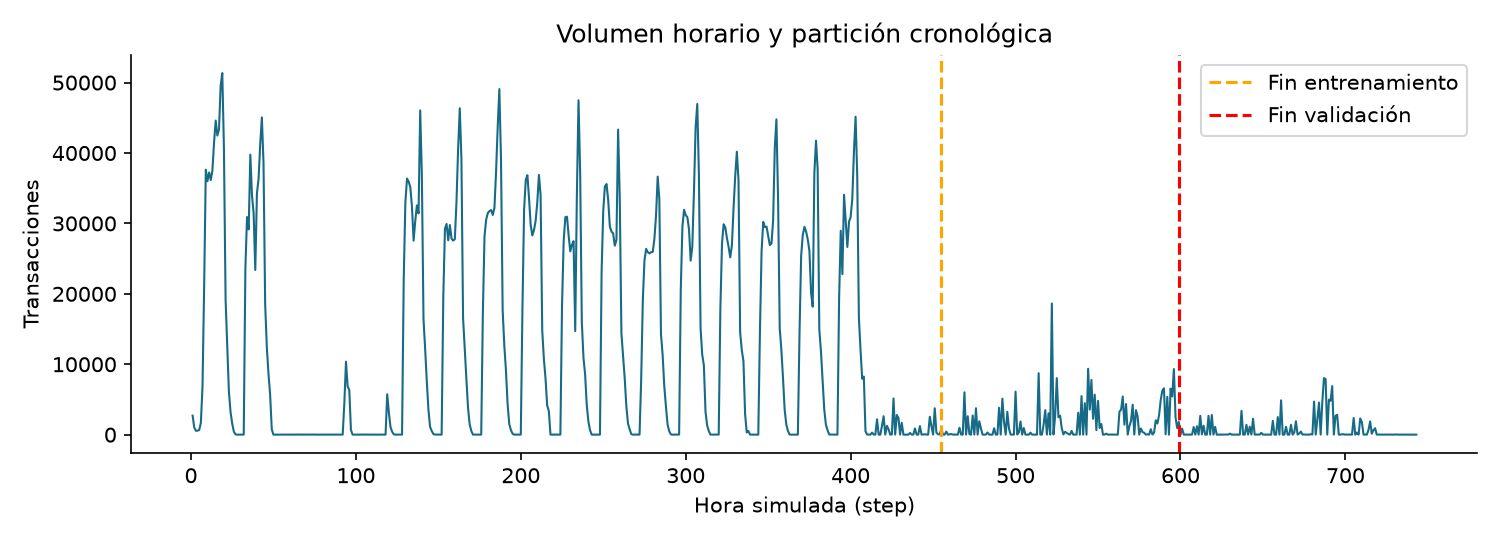

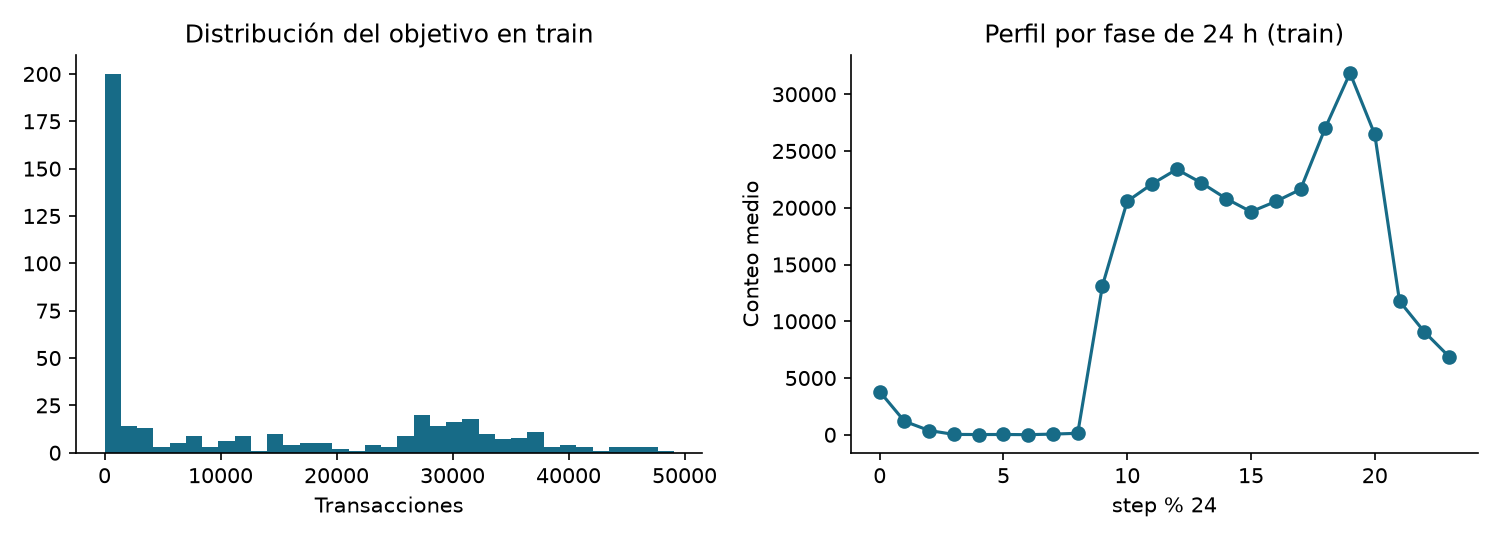

In [4]:
display(pd.read_csv(ROOT/'results/descriptive.csv'))
display(pd.read_csv(ROOT/'results/regime_summary.csv'))
display(Image(filename=str(ROOT/'results/figures/series.png')))
display(Image(filename=str(ROOT/'results/figures/eda.png')))

## 5. Pruebas de hipótesis e interpretación

Se plantean dos contrastes exploratorios, con α=0,05, usando únicamente entrenamiento y el modelo lineal temporal sin recorte. H0_1: los coeficientes de lag_1 y lag_24 son simultáneamente cero, condicionados por variables temporales. H0_2: los cinco coeficientes temporales son simultáneamente cero, condicionados por los rezagos.

Se estima OLS con covarianza HAC/Newey-West, maxlags=24 y corrección de muestra; luego se aplican contrastes Wald y ajuste Holm para dos hipótesis. Se rechazan ambas H0; para rezagos el p numérico se redondea a cero por subdesbordamiento (no probabilidad exactamente nula); para temporales p ajustado≈8,92×10^-15. Los coeficientes y sus IC95% HAC se exportan. La significación temporal dentro de train no garantiza mejora futura: la variante temporal empeoró el MAE de validación.

HAC contempla heterocedasticidad y dependencia de corto plazo bajo supuestos asintóticos; no resuelve cambios estructurales, endogeneidad ni estabilidad. Ljung-Box de residuos a 24 horas es diagnóstico adicional, con p nominal y sin usarlo como tercer contraste confirmatorio. Los hallazgos transaccionales del Laboratorio 2 se conservan en references, separados de estas pruebas nuevas.

In [5]:
display(pd.read_csv(ROOT/'results/hypotheses.csv'))
display(pd.read_csv(ROOT/'results/coefficients_HAC.csv'))
display(pd.read_csv(ROOT/'results/residual_ljungbox_train.csv'))

,hipotesis,H0,estadistico,p_HAC,p_Holm,rechaza_005
0,rezagos,Todos los coeficientes del grupo son cero,1507.501951,0.000000e+00,0.000000e+00,True
1,temporales,Todos los coeficientes del grupo son cero,75.088249,8.916692e-15,8.916692e-15,True


,variable,coef,se_HAC,p_HAC,IC95_inf,IC95_sup
0,const,98.081250,1284.345406,9.391273e-01,-2419.189490,2615.351989
1,lag_1,0.782431,0.079221,5.262069e-23,0.627160,0.937701
2,lag_24,0.198750,0.081440,1.466958e-02,0.039130,0.358370
3,sin24,1207.795044,573.068702,3.506629e-02,84.601027,2330.989061
4,cos24,-2511.248516,585.825799,1.813622e-05,-3659.445983,-1363.051048
5,sin12,-259.298740,262.290473,3.228619e-01,-773.378621,254.781140
6,cos12,-826.538765,227.996804,2.887146e-04,-1273.404289,-379.673241
7,step,-0.549984,3.722495,8.825432e-01,-7.845941,6.745973


,Unnamed: 0,lb_stat,lb_pvalue
0,24,360.16054,1.067364e-61


## 6. Construcción de pipelines

Para cada candidato: selección explícita de columnas -> StandardScaler -> LinearRegression con intercepto. Las filas con rezagos iniciales faltantes se excluyen antes de la partición; no hay imputación con información futura. El escalamiento se aprende dentro del pipeline para evitar fuga. En OLS sin regularización escalar no debe mejorar por sí solo el rendimiento: aporta coherencia al proceso y estabilidad numérica.

Modelo A: β0 + β1 lag_1 + β24 lag_24. Modelo B: añade step y armónicos de 24 y 12 horas. La regla de salida max(0, y_estimado) se define antes de evaluar, porque el objetivo es un conteo no negativo; el modelo ajustado sigue siendo regresión lineal, con posprocesamiento explícito. Se reportan también métricas sin recorte para auditar esta decisión. No se redondean predicciones al calcular errores.

Las transformaciones temporales son deterministas, conocidas anticipadamente. Los datos reales observados de horas previas se permiten en evaluación de una hora. Un horizonte fijo utiliza pronósticos recursivos y jamás inserta los conteos reales futuros.

In [6]:
a=int(len(x)*.6); b=int(len(x)*.8)
train,val,test=x.iloc[:a],x.iloc[a:b],x.iloc[b:]
kind=summary['modelo_seleccionado_validacion_MAE']
model_train=fit_model(train,kind)
assert np.allclose(model_train['escala'].mean_,train[columns(kind)].mean())
display(model_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escala', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['lag_1','lag_24']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 7. Entrenamiento de modelos

Primero se realiza validación temporal expansiva dentro de entrenamiento: tres bloques de 72 horas con train creciente. Los resultados quedan en cv_metrics.csv; sirven para describir estabilidad interna. Los dos candidatos y la regla de recorte son fijos, sin búsqueda de hiperparámetros. Se elige el candidato lineal por MAE en validación: gana lineal_lags (1.938,37 frente a 2.304,44 del temporal). La variante temporal se conserva como contraste requerido y su deterioro se informa explícitamente.

Baselines: media del entrenamiento; persistencia de la hora anterior; repetición de hace 24 horas; repetición de hace 168 horas; promedio de hasta siete observaciones previas de la misma fase diaria. En validación y prueba hay historia suficiente para los siete ciclos. El baseline elegido por MAE de validación es estacional_24 (1.780,71): ya supera al lineal en ese bloque.

Después se reajustan candidatos con train+validación (steps 25-599), se congelan parámetros y se evalúa test una sola vez como protocolo final, sin cambiar selección por lo observado allí. La aplicación reajusta el candidato lineal elegido con las 719 filas, separado del ajuste utilizado para medir test. Se muestran otros candidatos en test como comparación descriptiva, sin reselección.

In [7]:
display(pd.read_csv(ROOT/'results/cv_metrics.csv'))
metrics=pd.read_csv(ROOT/'results/metrics.csv')
display(metrics[metrics.etapa=='validacion'])
model_test=fit_model(x.iloc[:b],kind)
assert x.iloc[:b].step.max()<test.step.min()

,fold,modelo,train_fin,val_inicio,val_fin,MAE,RMSE,MAPE_pct,MAPE_n,R2,WAPE_pct
0,1,lineal_lags,239,240,311,3351.176825,5757.684075,620.947346,72,0.843913,20.155080
1,1,lineal_temporal,239,240,311,3435.844742,5256.949666,7661.573466,72,0.869882,20.664301
2,2,lineal_lags,311,312,383,3145.029495,5190.897142,616.578168,72,0.868754,19.281023
3,2,lineal_temporal,311,312,383,3414.731578,4866.038179,7212.837621,72,0.884667,20.934468
4,3,lineal_lags,383,384,455,3491.002177,5229.337781,11100.274915,72,0.807098,54.448245
5,3,lineal_temporal,383,384,455,4056.342852,5377.153410,16157.186471,72,0.796038,63.265715


,etapa,modelo,MAE,RMSE,MAPE_pct,MAPE_n,R2,WAPE_pct
0,validacion,lineal_lags_sin_recorte,1956.850164,3243.124677,5634.596293,144,-0.477762,117.739208
1,validacion,lineal_temporal_sin_recorte,2858.515505,3768.902669,11525.420459,144,-0.995754,171.990353
2,validacion,media_train,11055.703258,11292.093449,56493.663754,144,-16.915381,665.196431
3,validacion,persistencia_1,2219.250000,3674.348946,7035.037856,144,-0.896872,133.527207
4,validacion,estacional_24,1780.708333,3162.226310,2584.501375,144,-0.404957,107.141156
5,validacion,estacional_168,13201.284722,19002.168010,52089.244311,144,-49.732169,794.291170
6,validacion,media_estacional_7,5589.315476,8972.685462,25300.665028,144,-10.311547,336.296355
7,validacion,lineal_lags,1938.369895,3234.981053,5552.024120,144,-0.470350,116.627292
8,validacion,lineal_temporal,2304.441458,3420.254663,9532.109163,144,-0.643592,138.652983


## 8. Evaluación del modelo

Protocolo principal: evaluación secuencial de una hora, 144 predicciones en steps 600-743. Se conocen los conteos anteriores hasta t-1; los parámetros no se actualizan dentro del bloque. Para lineal_lags: MAE=1,040.06, RMSE=1,702.59, MAPE=7,379.64% y R²=-0.2222. WAPE=144.58%. Las tablas conservan precisión completa.

Frente al baseline estacional_24 seleccionado en validación, el MAE de prueba baja 26.83% (1.421,38 a 1.040,06). Sin embargo, persistencia_1 obtiene MAE 1.003,33, menor que el lineal, aunque su RMSE es mayor (1.800,72). No puede afirmarse que la regresión gane a todos los baselines. R² negativo significa SSE mayor que la referencia retrospectiva de la media real del bloque; esa media test no sería conocida para pronosticar.

MAPE=100·media(|y-ŷ|/|y|) solo para y distinto de cero; MAPE_n informa la cantidad válida (144 en test). Aquí no hay ceros, pero hay muchos conteos mínimos, que inflan el porcentaje. MAE mide error absoluto típico en transacciones; RMSE penaliza más los errores grandes. WAPE=100·Σ|error|/Σ|y| complementa MAPE, sin ocultar errores grandes.

Contraste a origen fijo: se predicen todas las 144 horas desde step 599 con rezagos recursivos. El MAE lineal sube a 1.963,35, RMSE a 2.242,74 y R² baja a -1,1207. La repetición recursiva de las últimas 24 horas obtiene MAE 2.047,74. Es una tarea diferente y más difícil; las métricas de una hora no deben publicitarse como rendimiento de 144 horas. No se ofrecen intervalos de incertidumbre sin validación.

,etapa,modelo,MAE,RMSE,MAPE_pct,MAPE_n,R2,WAPE_pct
9,test,lineal_lags_sin_recorte,1040.060824,1702.591181,7379.636113,144,-0.222216,144.576999
10,test,lineal_temporal_sin_recorte,1850.956642,2229.823386,14849.214023,144,-1.096371,257.298179
11,test,media_train,9167.181534,9295.643519,77354.414439,144,-35.432262,1274.313542
12,test,persistencia_1,1003.333333,1800.718672,7288.206826,144,-0.367159,139.471576
13,test,estacional_24,1421.375000,2505.297249,7401.160077,144,-1.646341,197.582802
14,test,estacional_168,1464.305556,2694.992012,9246.210181,144,-2.062261,203.550501
15,test,media_estacional_7,1282.361111,1857.596470,9711.530077,144,-0.454889,178.258729
16,test,lineal_lags,1040.060824,1702.591181,7379.636113,144,-0.222216,144.576999
17,test,lineal_temporal,1365.841484,1946.830480,11348.915655,144,-0.598025,189.863187


,modelo,protocolo,MAE,RMSE,MAPE_pct,MAPE_n,R2,WAPE_pct
0,lineal_lags,origen_fijo_test,1963.350792,2242.737417,15837.435765,144,-1.120724,272.921889
1,estacional_24,origen_fijo_test,2047.743056,3164.167370,16365.695389,144,-3.221299,284.653107


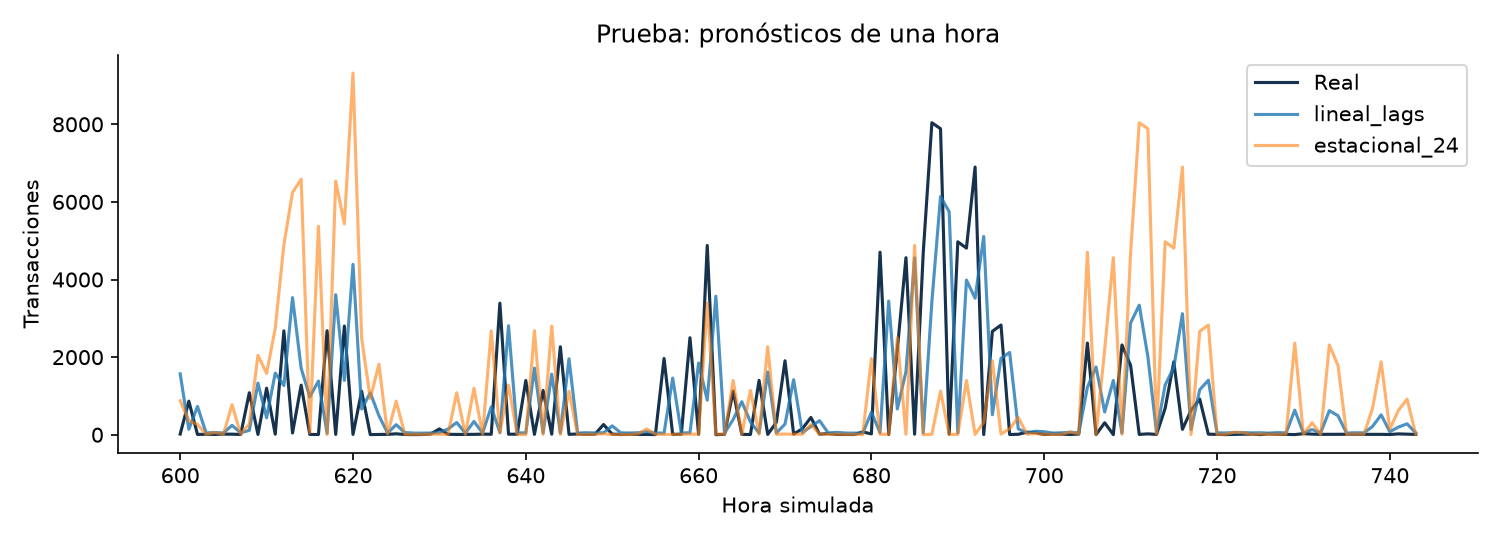

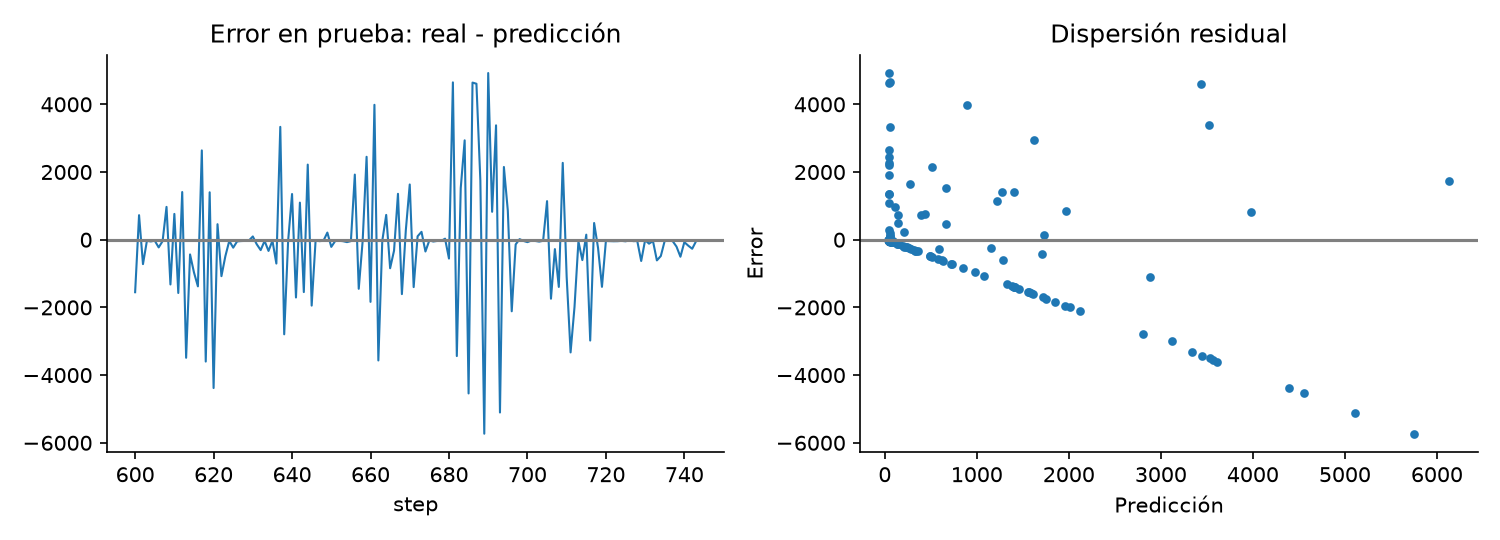

MAE         1040.060824
RMSE        1702.591181
MAPE_pct    7379.636113
MAPE_n       144.000000
R2            -0.222216
WAPE_pct     144.576999
dtype: float64

In [8]:
display(metrics[metrics.etapa=='test'])
display(pd.read_csv(ROOT/'results/recursive_metrics.csv'))
for image in ['test.png','residuals.png']: display(Image(filename=str(ROOT/'results/figures'/image)))
# Contraste independiente con fórmulas explícitas.
y=test.y.to_numpy(); pred=predict(model_test,test,kind)
assert np.isclose(np.abs(y-pred).mean(),summary['test_MAE_lineal'])
display(pd.Series(scores(y,pred)))

## 9. Conclusiones

Se construyó un proceso reproducible de regresión lineal supervisada sobre el mismo objetivo horario de los laboratorios anteriores. Los rezagos de 1 y 24 horas son conocidos a tiempo de predicción y están asociados al objetivo en entrenamiento. Añadir variables temporales conocidas no mejoró el MAE de validación, pese a su significación en el contraste exploratorio; se conserva la variante simple para predicción.

El rendimiento absoluto es insuficiente para uso operativo: R² negativo, MAPE y WAPE muy altos y dependencia del régimen de actividad. La mejora frente al baseline estacional elegido en validación no equivale a superioridad universal. La persistencia de una hora debe mantenerse como referencia fuerte. La selección lineal responde al objetivo académico, no a una afirmación de ser el mejor modelo de producción.

El horizonte recursivo acumula errores y no reemplaza una evaluación específica por horizonte. Próximos pasos: más datos que cubran distintos regímenes, ventanas móviles y detección de cambios, regresión de conteos o transformación del objetivo con corrección adecuada y, como contraste opcional, SARIMA. Estas alternativas requerirían nueva validación temporal antes de cualquier afirmación de mejora.

La app permite filtrar horas, comparar modelos, introducir rezagos manuales y pronosticar de 1 a 72 horas. No se modificó el repositorio remoto. Los resultados anteriores se preservan en references/laboratorio_2; el CSV original no se distribuye porque no está disponible. El proyecto funciona sin él usando la serie agregada de 743 filas.

In [9]:
deployment=fit_model(x,kind)
forecast=recursive(deployment,d,24,kind)
display(forecast)
forecast.plot(x='step',y='prediccion',title='Pronóstico recursivo desde step 743'); plt.show()

,step,prediccion
0,744,20.818931
1,745,28.600742
2,746,35.730286
3,747,41.888747
4,748,46.346403
5,749,47.078193
6,750,52.098480
7,751,53.237518
8,752,53.563029
9,753,52.301775


C:\Users\david.nuncira\AppData\Local\Temp\ipykernel_25696\1655678738.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  forecast.plot(x='step',y='prediccion',title='Pronóstico recursivo desde step 743'); plt.show()


### Fuentes y reproducción
- Guía original: `references/Laboratorio_3.pdf`.
- [Repositorio Laboratorio 2](https://github.com/david-nuncira/laboratorio_2_paysim): README, serie, resumen y notebooks; huellas en `references/provenance.json`.
- [Pipeline, scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).
- [TimeSeriesSplit, scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
- [Covarianza robusta, statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html).

La evidencia del Laboratorio 1 se limita al esquema y resumen preservados por Laboratorio 2; no se afirma haber revisado un informe adicional del primero.